In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
from scipy.io import loadmat

def load_biomass_data(
    parent_path,
    band_opt,
    heading,
    acquisition_mode,
    polarimetric_channel,
    
):

    # Loading normalized SAR intensity data cube
    if band_opt == 'P':
        # Loading angles
        angles_path = f"{parent_path}/{band_opt}/PowerCubeGeocod/AnglesUTM.mat"
        angles_data = loadmat(angles_path)
        IncAngleUTM = angles_data['IncAngleUTM']
        easting_axis = angles_data['easting_axis'].squeeze()
        northing_axis = angles_data['northing_axis'].squeeze()

        # Loading LiDAR data
        lidar_path = f"{parent_path}/{band_opt}/PowerCubeGeocod/LidarUTM.mat"
        lidar_data = loadmat(lidar_path)
        LidarCHM = lidar_data['LidarCHM']
        
        # Loading TomoDeRamped or TomoDeRampedDeBiased data
        pcube_norm_path = f"{parent_path}/{band_opt}/PowerCubeGeocod/PcubeNormUTM.mat"
        pcube_norm_data = loadmat(pcube_norm_path)
        PcubeNormUTM = pcube_norm_data['PcubeNormUTM']
        z_axis = pcube_norm_data['z_axis'].squeeze()
    
    elif band_opt in ['L_Mono', 'L_Bi']:
        # Loading angles
        angles_path = f"{parent_path}/L/PowerCubeGeocod/AnglesUTM.mat"
        angles_data = loadmat(angles_path)
        IncAngleUTM = angles_data['IncAngleUTM']
        easting_axis = angles_data['easting_axis'].squeeze()
        northing_axis = angles_data['northing_axis'].squeeze()

        # Loading LiDAR data
        lidar_path = f"{parent_path}/L/PowerCubeGeocod/LidarUTM.mat"
        lidar_data = loadmat(lidar_path)
        LidarCHM = lidar_data['LidarCHM']
        
        # Loading TomoDeRamped or TomoDeRampedDeBiased data
        pcube_norm_path = f"{parent_path}/L/PowerCubeGeocod/PcubeNormUTM.mat"
        pcube_norm_data = loadmat(pcube_norm_path)
        PcubeNormUTM = pcube_norm_data['PcubeNormUTM']
        z_axis = pcube_norm_data['z_axis'].squeeze()

    elif band_opt == 'PL':
        
        # Loading angles
        angles_path_P = f"{parent_path}/P/PowerCubeGeocod/AnglesUTM.mat"
        angles_data_P = loadmat(angles_path_P)
        IncAngleUTM_P = angles_data_P['IncAngleUTM']
        easting_axis_P = angles_data_P['easting_axis'].squeeze()
        northing_axis_P = angles_data_P['northing_axis'].squeeze()
        angles_path_L = f"{parent_path}/L/PowerCubeGeocod/AnglesUTM.mat"
        angles_data_L = loadmat(angles_path_L)
        IncAngleUTM_L = angles_data_L['IncAngleUTM']
        easting_axis_L = angles_data_L['easting_axis'].squeeze()
        northing_axis_L = angles_data_L['northing_axis'].squeeze()

        # Loading LiDAR data (LiDAR data is same between P and L bands)
        lidar_path = f"{parent_path}/P/PowerCubeGeocod/LidarUTM.mat"
        lidar_data = loadmat(lidar_path)
        LidarCHM = lidar_data['LidarCHM']
        
        pcube_norm_path_P = f"{parent_path}/P/PowerCubeGeocod/PcubeNormUTM.mat"
        pcube_norm_path_L = f"{parent_path}/L/PowerCubeGeocod/PcubeNormUTM.mat"
        pcube_norm_data_P = loadmat(pcube_norm_path_P)
        pcube_norm_data_L = loadmat(pcube_norm_path_L)
        PcubeNormUTM_P = pcube_norm_data_P['PcubeNormUTM']
        PcubeNormUTM_L = pcube_norm_data_L['PcubeNormUTM']
        z_axis_P = pcube_norm_data_P['z_axis'].squeeze()        
        z_axis_L = pcube_norm_data_L['z_axis'].squeeze()        
        
    # Loading SAR intensity data cube
    if band_opt == 'P':
        sar_intensity_path = f"{parent_path}{band_opt}/PowerCubeGeocod/PcubeDeRampedUTM.mat"
        sar_intensity_data = loadmat(sar_intensity_path)
        PcubeDeRampedUTM = sar_intensity_data['PcubeDeRampedUTM']
    elif band_opt in ['L_Mono', 'L_Bi']:
        sar_intensity_path = f"{parent_path}{band_opt}/PowerCubeGeocod/PcubeDeRampedDeBiasedUTM.mat"
        sar_intensity_data = loadmat(sar_intensity_path)
        PcubeDeRampedDeBiasedUTM = sar_intensity_data['PcubeDeRampedDeBiasedUTM']
    elif band_opt == 'PL':
        sar_intensity_path_p = f"{parent_path}/P/PowerCubeGeocod/PcubeDeRampedUTM.mat"
        sar_intensity_path_l = f"{parent_path}/L/PowerCubeGeocod/PcubeDeRampedDeBiasedUTM.mat"
        sar_intensity_data_p = loadmat(sar_intensity_path_p)
        sar_intensity_data_l = loadmat(sar_intensity_path_l)
        PcubeDeRampedUTM = sar_intensity_data_p['PcubeDeRampedUTM']
        PcubeDeRampedDeBiasedUTM = sar_intensity_data_l['PcubeDeRampedDeBiasedUTM']    

    # Determine the indices based on string options
    head_ind = 1 if heading == 'NW' else 2
    mono_bi_ind = 1 if acquisition_mode == 'monostatic' else 2
    pol_ind = {'HH': 1, 'HV': 2, 'VV': 3}[polarimetric_channel]

    if band_opt == 'P':
        return {
            'IncAngleUTM': IncAngleUTM,
            'easting_axis': easting_axis,
            'northing_axis': northing_axis,
            'LidarCHM': LidarCHM,
            'PcubeNormUTM': PcubeNormUTM,
            'z_axis': z_axis,
            'PcubeDeRampedUTM': PcubeDeRampedUTM,
            'head_ind': head_ind,
            'mono_bi_ind': mono_bi_ind,
            'pol_ind': pol_ind
        }
    elif band_opt in ['L_Mono', 'L_Bi']:
        return {
            'IncAngleUTM': IncAngleUTM,
            'easting_axis': easting_axis,
            'northing_axis': northing_axis,
            'LidarCHM': LidarCHM,
            'PcubeNormUTM': PcubeNormUTM,
            'z_axis': z_axis,
            'PcubeDeRampedDeBiasedUTM': PcubeDeRampedDeBiasedUTM,
            'head_ind': head_ind,
            'mono_bi_ind': mono_bi_ind,
            'pol_ind': pol_ind
        }        
    elif band_opt == 'PL':
        return {
            'IncAngleUTM_P': IncAngleUTM_P,
            'IncAngleUTM_L': IncAngleUTM_L,
            'easting_axis_P': easting_axis_P,
            'easting_axis_L': easting_axis_L,
            'northing_axis_P': northing_axis_P,
            'northing_axis_L': northing_axis_L,
            'LidarCHM': LidarCHM,
            'PcubeNormUTM_P': PcubeNormUTM_P,
            'PcubeNormUTM_L': PcubeNormUTM_L,
            'z_axis_P': z_axis_P,
            'z_axis_L': z_axis_L,
            'PcubeDeRampedUTM': PcubeDeRampedUTM,
            'PcubeDeRampedDeBiasedUTM': PcubeDeRampedDeBiasedUTM,
            'head_ind': head_ind,
            'mono_bi_ind': mono_bi_ind,
            'pol_ind': pol_ind
        }
    else:
        raise ValueError("Invalid value for band_opt: must be 'P', 'L', or 'PL'")

In [26]:
# Example usage
parent_path = '/home/takataka_ju/data/tomosar-matlab/'
band_opt = 'PL'
heading = 'NW'
acquisition_mode = 'monostatic'
polarimetric_channel = 'HV'

data = load_biomass_data(parent_path, band_opt, heading, acquisition_mode, polarimetric_channel)

# Access the returned objects
if band_opt == 'P':
    IncAngleUTM = data['IncAngleUTM']
    easting_axis = data['easting_axis']
    northing_axis = data['northing_axis']
    LidarCHM = data['LidarCHM']
    PcubeNormUTM = data['PcubeNormUTM']
    z_axis = data['z_axis']
    PcubeDeRampedUTM = data['PcubeDeRampedUTM']
    head_ind = data['head_ind']
    mono_bi_ind = data['mono_bi_ind']
    pol_ind = data['pol_ind']
elif band_opt == 'L_Mono':
    IncAngleUTM = data['IncAngleUTM']
    easting_axis = data['easting_axis']
    northing_axis = data['northing_axis']
    LidarCHM = data['LidarCHM']
    PcubeNormUTM = data['PcubeNormUTM']
    z_axis = data['z_axis']
    PcubeDeRampedUTM_Original = data['PcubeDeRampedDeBiasedUTM']
    PcubeDeRampedDeBiasedUTM_Mono = PcubeDeRampedUTM_Original[:,:,:,:,:,0]
    head_ind = data['head_ind']
    mono_bi_ind = data['mono_bi_ind']
    pol_ind = data['pol_ind'] 
elif band_opt == 'L_Bi':
    IncAngleUTM = data['IncAngleUTM']
    easting_axis = data['easting_axis']
    northing_axis = data['northing_axis']
    LidarCHM = data['LidarCHM']
    PcubeNormUTM = data['PcubeNormUTM']
    z_axis = data['z_axis']
    PcubeDeRampedUTM_Original = data['PcubeDeRampedDeBiasedUTM']
    PcubeDeRampedDeBiasedUTM_Bi = PcubeDeRampedUTM_Original[:,:,:,:,:,1]
    head_ind = data['head_ind']
    mono_bi_ind = data['mono_bi_ind']
    pol_ind = data['pol_ind'] 
elif band_opt == 'PL':
    IncAngleUTM_P = data['IncAngleUTM_P']
    IncAngleUTM_L = data['IncAngleUTM_L']
    easting_axis_P = data['easting_axis_P']
    easting_axis_L = data['easting_axis_L']
    northing_axis_P = data['northing_axis_P']
    northing_axis_L = data['northing_axis_L']
    LidarCHM = data['LidarCHM']
    PcubeNormUTM_P = data['PcubeNormUTM_P']
    PcubeNormUTM_L = data['PcubeNormUTM_L']
    z_axis_P = data['z_axis_P']
    z_axis_L = data['z_axis_L']
    PcubeDeRampedUTM = data['PcubeDeRampedUTM']
    PcubeDeRampedUTM_Original = data['PcubeDeRampedDeBiasedUTM']
    PcubeDeRampedDeBiasedUTM_Mono = PcubeDeRampedUTM_Original[:,:,:,:,0,:]
    PcubeDeRampedDeBiasedUTM_Bi = PcubeDeRampedUTM_Original[:,:,:,:,1,:]
    PcubeDeRampedDeBiasedUTM = data['PcubeDeRampedDeBiasedUTM']
    head_ind = data['head_ind']
    mono_bi_ind = data['mono_bi_ind']
    pol_ind = data['pol_ind']
else:
    print('select: P, L_Mono, L_Bi, PL')   


PcubeDeRampedUTM.shape (326, 840, 36, 3, 2)


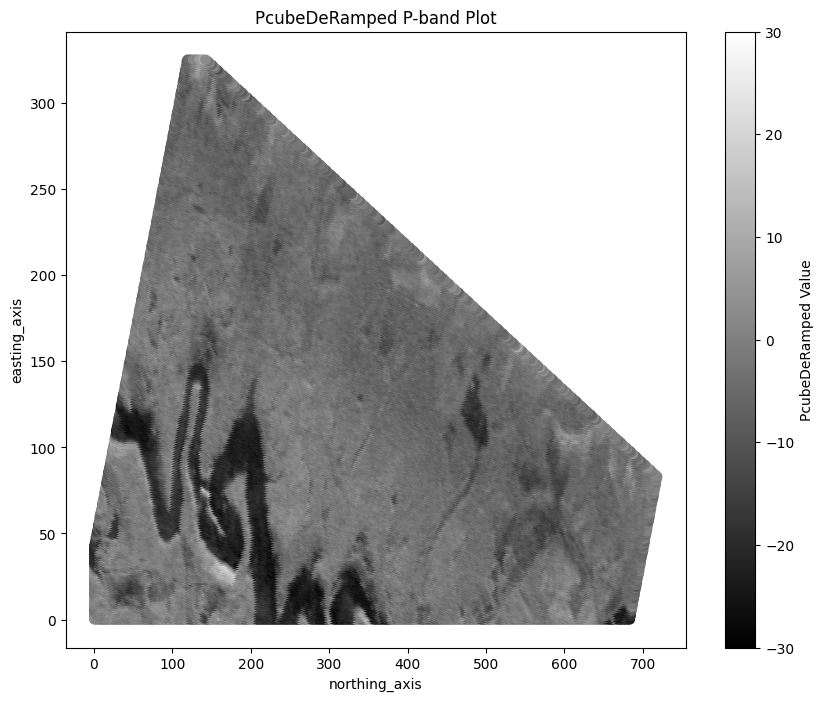

In [29]:
print('PcubeDeRampedUTM.shape', PcubeDeRampedUTM.shape)

x = np.arange(PcubeDeRampedUTM.shape[1])  # easting_axis
y = np.arange(PcubeDeRampedUTM.shape[0])  # northing_axis
X, Y = np.meshgrid(x, y)
z = PcubeDeRampedUTM[:,:,0,0,0]

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X, Y, c=z, cmap='gray', vmin=-30, vmax=30)
plt.colorbar(scatter, label='PcubeDeRamped Value')
plt.xlabel('northing_axis')
plt.ylabel('easting_axis')
plt.title('PcubeDeRamped P-band Plot')
plt.show()

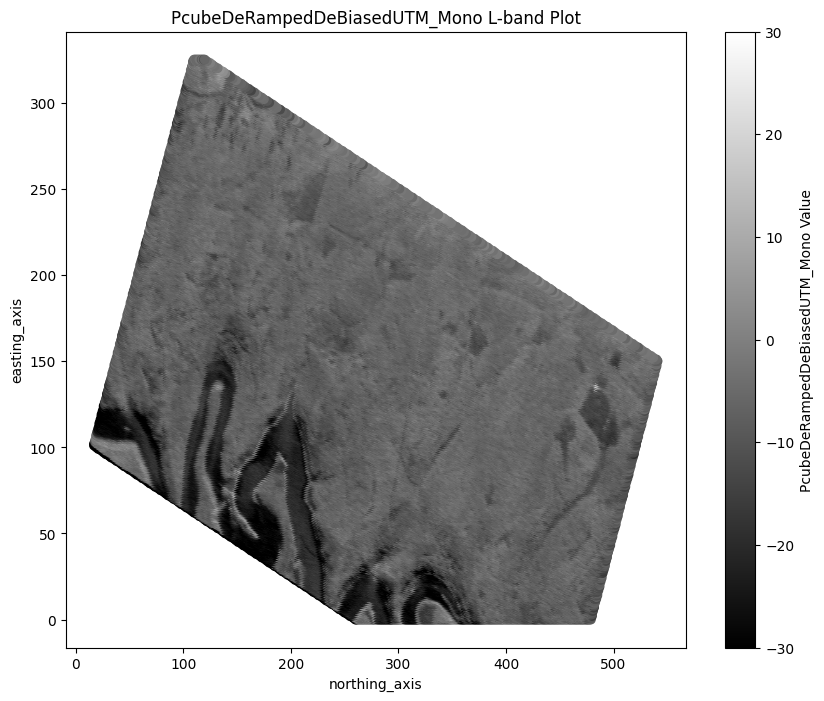

In [30]:
PcubeDeRampedDeBiasedUTM_Mono.shape

x = np.arange(PcubeDeRampedDeBiasedUTM_Mono.shape[1])  # easting_axis
y = np.arange(PcubeDeRampedDeBiasedUTM_Mono.shape[0])  # northing_axis
X, Y = np.meshgrid(x, y)
z = PcubeDeRampedDeBiasedUTM_Mono[:,:,0,0,0]

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X, Y, c=z, cmap='gray', vmin=-30, vmax=30)
plt.colorbar(scatter, label='PcubeDeRampedDeBiasedUTM_Mono Value')
plt.xlabel('northing_axis')
plt.ylabel('easting_axis')
plt.title('PcubeDeRampedDeBiasedUTM_Mono L-band Plot')
plt.show()

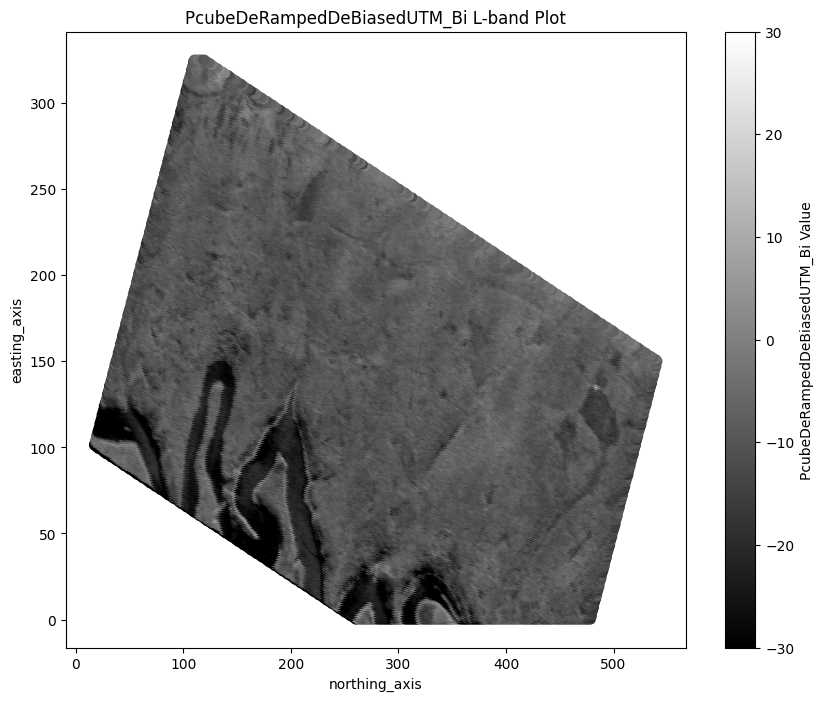

In [31]:
PcubeDeRampedDeBiasedUTM_Bi.shape

x = np.arange(PcubeDeRampedDeBiasedUTM_Bi.shape[1])  # easting_axis
y = np.arange(PcubeDeRampedDeBiasedUTM_Bi.shape[0])  # northing_axis
X, Y = np.meshgrid(x, y)
z = PcubeDeRampedDeBiasedUTM_Bi[:,:,0,0,0]

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X, Y, c=z, cmap='gray', vmin=-30, vmax=30)
plt.colorbar(scatter, label='PcubeDeRampedDeBiasedUTM_Bi Value')
plt.xlabel('northing_axis')
plt.ylabel('easting_axis')
plt.title('PcubeDeRampedDeBiasedUTM_Bi L-band Plot')
plt.show()

In [9]:
import numpy as np
import pandas as pd

def lidar_cube_to_table(lidar_cube):
    """
    Converts a LiDAR cube into a table with columns x, y, and lidar.

    Parameters:
    - lidar_cube: np.array of shape (x_dim, y_dim) where dimensions are (x, y, lidar)

    Returns:
    - pd.DataFrame with columns [x, y, lidar]
    """
    x_dim, y_dim = lidar_cube.shape
    records = []

    for x in range(x_dim):
        for y in range(y_dim):
            lidar_value = lidar_cube[x, y]
            records.append([x, y, lidar_value])

    # Create DataFrame
    df = pd.DataFrame(records, columns=['x', 'y', 'lidar'])
    return df

# Example usage

lidar_df = lidar_cube_to_table(LidarCHM)
print(lidar_df)


NameError: name 'LidarCHM' is not defined

In [7]:
# percentage of nulls
sum(lidar_df["lidar"].isna())/lidar_df.shape[0]

0.2204754601226994

In [8]:
# import matplotlib as mpl
# plt.figure(figsize=(10, 6))
# cmap = mpl.colormaps.get_cmap('viridis')  # viridis is the default colormap for imshow
# cmap.set_bad(color='red')
# plt.imshow(LidarCHM, cmap=cmap)
# #plt.imshow(LidarCHM, cmap=cmap)
# plt.colorbar(label='LidarMap (mts)')
# plt.xlabel('Azimuth (meters)')
# plt.ylabel('Ground Range (meters)')
# plt.title('Lidar NaNs')
# plt.show()

In [9]:
from shapely.geometry import Point, Polygon
# Define the coordinates of the polygon (example polygon coordinates)
polygon_coords = [(50, 40), (350, 0), (710, 0), (710, 250), (50, 300)]
polygon = Polygon(polygon_coords)

In [10]:
print(type(LidarCHM))
LidarCHM.shape

<class 'numpy.ndarray'>


(326, 840)

In [11]:
# Access the correct coordinate variables (assuming they are named 'x' and 'y')
rows, cols = LidarCHM.shape
mask = np.zeros(LidarCHM.shape, dtype=bool)


In [12]:
x_coords, y_coords = np.meshgrid(np.arange(cols), np.arange(rows))

In [13]:
import xarray as xr
from matplotlib.patches import Polygon as MplPolygon

# Check if each point is inside the polygon
for i in range(rows):
    for j in range(cols):
        point = Point(x_coords[i, j], y_coords[i, j])
        if polygon.contains(point):
            mask[i, j] = True

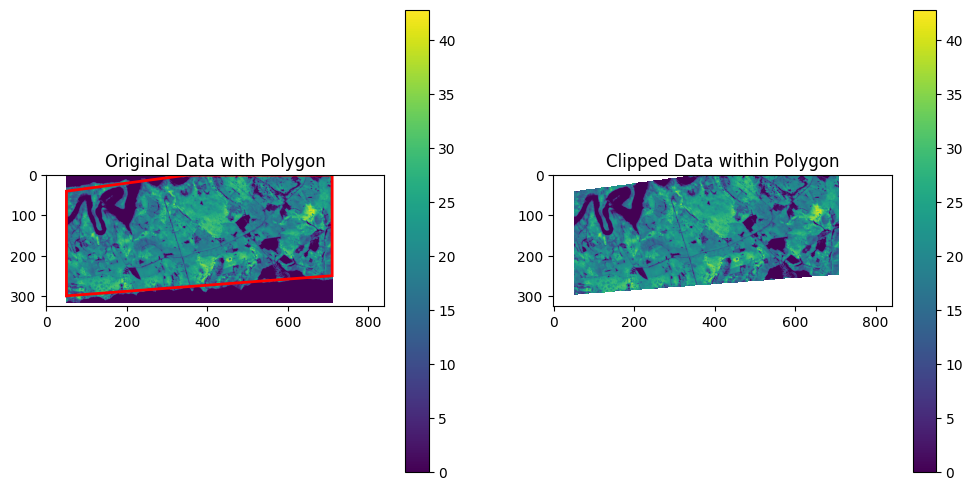

In [14]:
clipped_data = np.full(LidarCHM.shape, np.nan)
clipped_data[mask] = LidarCHM[mask]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.set_title('Original Data with Polygon')
c1 = ax1.imshow(LidarCHM, cmap='viridis')
fig.colorbar(c1, ax=ax1)

polygon_patch = MplPolygon(polygon_coords, closed=True, edgecolor='red', fill=False, linewidth=2)
ax1.add_patch(polygon_patch)

ax2.set_title('Clipped Data within Polygon')
c2 = ax2.imshow(clipped_data, cmap='viridis')
fig.colorbar(c2, ax=ax2)

plt.show()

In [15]:
# import matplotlib as mpl
# plt.figure(figsize=(10, 6))
# cmap = mpl.colormaps.get_cmap('viridis')  # viridis is the default colormap for imshow
# cmap.set_bad(color='red')
# plt.imshow( PcubeDeRampedUTM[:,:,0,0,0] , cmap=cmap)
# #plt.imshow(LidarCHM, cmap=cmap)
# plt.colorbar(label='TomoCubes')
# plt.xlabel('Azimuth (meters)')
# plt.ylabel('Ground Range (meters)')
# plt.title('TomoCubes NaNs')
# plt.show()

In [16]:
# import matplotlib as mpl
# plt.figure(figsize=(10, 6))
# cmap = mpl.colormaps.get_cmap('viridis')  # viridis is the default colormap for imshow
# cmap.set_bad(color='red')
# plt.imshow( PcubeDeRampedUTM[:,:,0,0,1] , cmap=cmap)
# #plt.imshow(LidarCHM, cmap=cmap)
# plt.colorbar(label='TomoCubes')
# plt.xlabel('Azimuth (meters)')
# plt.ylabel('Ground Range (meters)')
# plt.title('TomoCubes NaNs')
# plt.show()

In [17]:
import numpy as np
import pandas as pd

def extract_z_vectors(data, band):
    """
    Extracts z vectors for each (x, y) point in the given data and stores them in a table with additional information.

    Parameters:
    - data: np.array of shape (326, 840, 36, 3, 2) where dimensions are (x, y, z, polarimetry, heading)

    Returns:
    - pd.DataFrame with columns [x, y, z_0, z_1, ..., z_n, heading, polarimetry] where z_n is the max value of z.
    """
    x_dim, y_dim, z_dim, pol_dim, head_dim = data.shape
    records = []

    for heading in range(head_dim):
        for polarimetry in range(pol_dim):
            for x in range(x_dim):
                for y in range(y_dim):
                    z_vector = data[x, y, :, polarimetry, heading]
                    record = [x, y] + z_vector.tolist() + [heading, polarimetry]
                    records.append(record)

    # Generate column names: x, y, z_P_0, z_P_1, ..., z_P_n, heading, polarimetry
    columns = ['x', 'y'] + [f'z_{band}_{i}' for i in range(z_dim)] + ['heading', 'polarimetry']
    
    df = pd.DataFrame(records, columns=columns)
    return df



# Example usage

# df = extract_z_vectors(PcubeDeRampedUTM[0:10, 0:10, :, :, :])
# print(df)


In [81]:
if band_opt == 'P':
    df = extract_z_vectors(PcubeDeRampedUTM, "P")
    print(df.shape)
elif band_opt == 'L_Mono':
    df = extract_z_vectors(PcubeDeRampedDeBiasedUTM_Mono, "L_Mono")
    print(df.shape)
elif band_opt == 'L_Bi':
    df = extract_z_vectors(PcubeDeRampedDeBiasedUTM_Bi, "L_Bi")
    print(df.shape)
elif band_opt == 'PL':
    df_P = extract_z_vectors(PcubeDeRampedUTM, "P")
    df_L_Mono = extract_z_vectors(PcubeDeRampedDeBiasedUTM_Mono, "L_Mono")
    df_L_Bi = extract_z_vectors(PcubeDeRampedDeBiasedUTM_Bi, "L_Bi")
    print('P-band df:', df_P.shape)        
    print('L-band Mono df:', df_L_Mono.shape)   
    print('L-band Bi df:', df_L_Bi.shape)   

P-band df: (1643040, 40)
L-band Mono df: (1643040, 40)
L-band Bi df: (1643040, 40)


In [82]:
if band_opt == 'P':
    print('None')
elif band_opt == 'L_Mono':
    print('None')
elif band_opt == 'L_Bi':
    print('None')
elif band_opt == 'PL':
    df = pd.merge(df_P, df_L_Mono, on=['x', 'y', 'heading', 'polarimetry'], how='inner')
    df = pd.merge(df, df_L_Bi, on=['x', 'y', 'heading', 'polarimetry'], how='inner')
    print('Merged Mono and Bi df:', df.shape)

Merged Mono and Bi df: (1643040, 112)


In [83]:
# Identify the columns corresponding to the z values
z_columns = [col for col in df.columns if col.startswith('z_')]
print(z_columns)

# Filter out rows where any z value is NaN
df_filtered = df.loc[~(df[z_columns].isna().any(axis=1))]

# Filter out rows where the value is less than -300dB
threshold = -300
df_filtered = df_filtered[(df_filtered > threshold).all(axis=1)]

print(df_filtered.shape)

['z_P_0', 'z_P_1', 'z_P_2', 'z_P_3', 'z_P_4', 'z_P_5', 'z_P_6', 'z_P_7', 'z_P_8', 'z_P_9', 'z_P_10', 'z_P_11', 'z_P_12', 'z_P_13', 'z_P_14', 'z_P_15', 'z_P_16', 'z_P_17', 'z_P_18', 'z_P_19', 'z_P_20', 'z_P_21', 'z_P_22', 'z_P_23', 'z_P_24', 'z_P_25', 'z_P_26', 'z_P_27', 'z_P_28', 'z_P_29', 'z_P_30', 'z_P_31', 'z_P_32', 'z_P_33', 'z_P_34', 'z_P_35', 'z_L_Mono_0', 'z_L_Mono_1', 'z_L_Mono_2', 'z_L_Mono_3', 'z_L_Mono_4', 'z_L_Mono_5', 'z_L_Mono_6', 'z_L_Mono_7', 'z_L_Mono_8', 'z_L_Mono_9', 'z_L_Mono_10', 'z_L_Mono_11', 'z_L_Mono_12', 'z_L_Mono_13', 'z_L_Mono_14', 'z_L_Mono_15', 'z_L_Mono_16', 'z_L_Mono_17', 'z_L_Mono_18', 'z_L_Mono_19', 'z_L_Mono_20', 'z_L_Mono_21', 'z_L_Mono_22', 'z_L_Mono_23', 'z_L_Mono_24', 'z_L_Mono_25', 'z_L_Mono_26', 'z_L_Mono_27', 'z_L_Mono_28', 'z_L_Mono_29', 'z_L_Mono_30', 'z_L_Mono_31', 'z_L_Mono_32', 'z_L_Mono_33', 'z_L_Mono_34', 'z_L_Mono_35', 'z_L_Bi_0', 'z_L_Bi_1', 'z_L_Bi_2', 'z_L_Bi_3', 'z_L_Bi_4', 'z_L_Bi_5', 'z_L_Bi_6', 'z_L_Bi_7', 'z_L_Bi_8', 'z_L_Bi_9',

In [21]:
df_filtered

,x,y,z_P_0,z_P_1,z_P_2,z_P_3,z_P_4,z_P_5,z_P_6,z_P_7,...,z_L_Bi_26,z_L_Bi_27,z_L_Bi_28,z_L_Bi_29,z_L_Bi_30,z_L_Bi_31,z_L_Bi_32,z_L_Bi_33,z_L_Bi_34,z_L_Bi_35
69393,82,513,-3.403221,-2.399017,-1.410504,-0.665860,-0.386070,-0.517967,-0.836508,-1.146693,...,-328.654359,-328.654359,-328.654359,-328.654359,-328.654359,-328.654359,-328.654359,-328.654359,-328.654359,-328.654359
70231,83,511,-0.929711,1.336782,3.140128,4.226899,4.725849,4.544723,3.821742,2.867857,...,-327.979149,-327.979149,-327.979149,-327.979149,-327.979149,-327.979149,-327.979149,-327.979149,-327.979149,-327.979149
70232,83,512,-7.300485,-6.375891,-3.441348,-0.357663,1.898731,3.295217,3.716822,3.354114,...,-328.196853,-328.196853,-328.196853,-328.196853,-328.196853,-328.196853,-328.196853,-328.196853,-328.196853,-328.196853
70233,83,513,-7.597341,-6.602725,-4.683629,-2.488977,-0.579043,0.809700,1.535236,1.638909,...,-328.573877,-328.573877,-328.573877,-328.573877,-328.573877,-328.573877,-328.573877,-328.573877,-328.573877,-328.573877
71068,84,508,-6.882927,-5.906209,-5.008993,-4.276194,-3.587281,-3.054930,-2.963422,-3.295390,...,-328.944914,-328.944914,-328.944914,-328.944914,-328.944914,-328.944914,-328.944914,-328.944914,-328.944914,-328.944914
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1601277,276,237,-9.284880,-8.808897,-7.739305,-6.351299,-5.229902,-4.704614,-4.991539,-6.113342,...,-18.511618,-18.130953,-16.396762,-14.141158,-12.544036,-11.929047,-12.642623,-14.549681,-16.266733,-16.187875
1601278,276,238,-13.814271,-12.571040,-11.042474,-9.660007,-8.564442,-7.846686,-7.517091,-7.604202,...,-12.999596,-13.398467,-13.758594,-12.944485,-11.754645,-10.955538,-10.960818,-11.353110,-11.643062,-11.821839
1602114,277,234,-9.566202,-7.572160,-5.986018,-4.816013,-4.081984,-3.915800,-4.289166,-4.883656,...,-15.354666,-14.441774,-13.230705,-12.522629,-12.647512,-12.858822,-13.183661,-14.144838,-15.331124,-15.719478
1602115,277,235,-6.583177,-5.708475,-4.898594,-4.167118,-3.629334,-3.498960,-3.851900,-4.796580,...,-14.234458,-14.551260,-15.331677,-16.001186,-15.290332,-13.744841,-13.273280,-14.803147,-17.705103,-17.610404


In [54]:
# merge filtered flattened data with the lidar data , remove any lidar nulls
mldata = df_filtered.merge(lidar_df, on=['x', 'y'])

cl_ml_data = mldata[~mldata['lidar'].isna()]

In [55]:
cl_ml_data.shape

(0, 41)

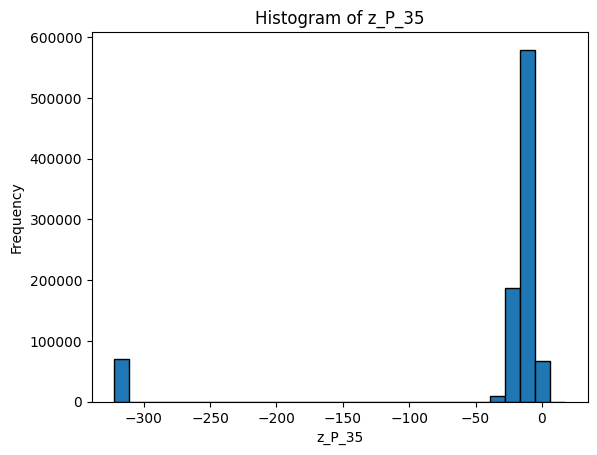

In [56]:
column_to_plot = 'z_P_35'  

plt.hist(df_P[column_to_plot], bins=30, edgecolor='black')
plt.title(f'Histogram of {column_to_plot}')
plt.xlabel(column_to_plot)
plt.ylabel('Frequency')
plt.show()

In [57]:
# 1. Separate the z columns
z_cols = [col for col in cl_ml_data.columns if col.startswith('z_')]

# 2. Melt the dataframe to long format for z values
df_melted = cl_ml_data.melt(id_vars=['x', 'y', 'polarimetry', 'lidar', 'heading'], 
                    value_vars=z_cols, 
                    var_name='z_index', 
                    value_name='z_value')

In [58]:
df_melted.shape
df_melted.columns

Index(['x', 'y', 'polarimetry', 'lidar', 'heading', 'z_index', 'z_value'], dtype='object')

In [59]:
# 3. Create a new column combining polarimetry and z_index
df_melted['pol_z'] = 'pol_' + df_melted['polarimetry'].astype(str) + '_' + df_melted['z_index']

# 4. Pivot the dataframe to create separate columns for each polarimetry-z combination
df_pivot = df_melted.pivot_table(index=['x', 'y', "lidar", 'heading'], 
                                    columns='pol_z', 
                                    values='z_value', 
                                    aggfunc='first')

In [60]:
df_pivot.shape

(0, 0)

In [61]:
# 5. Reset the index to turn x, y, label, and heading back into columns
df_pivot.reset_index(inplace=True)

# 6. Flatten the column names
df_pivot.columns.name = None

In [62]:
print(df_pivot.shape)
print(df_pivot.columns)
# print(df_pivot.duplicated(subset=['x', 'y']).sum())

(0, 4)
Index(['x', 'y', 'lidar', 'heading'], dtype='object')


## Plot df with x and y

In [31]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [37]:
# Create a GeoDataFrame
gdf_filtered = gpd.GeoDataFrame(
    df_filtered, geometry=gpd.points_from_xy(df_filtered.x, df_filtered.y))

# Set the coordinate reference system (CRS) if known, for example, EPSG:4326
gdf_filtered.set_crs(epsg=25832, inplace=True)

,x,y,z_P_0,z_P_1,z_P_2,z_P_3,z_P_4,z_P_5,z_P_6,z_P_7,...,z_L_Bi_27,z_L_Bi_28,z_L_Bi_29,z_L_Bi_30,z_L_Bi_31,z_L_Bi_32,z_L_Bi_33,z_L_Bi_34,z_L_Bi_35,geometry
69393,82,513,-3.403221,-2.399017,-1.410504,-0.665860,-0.386070,-0.517967,-0.836508,-1.146693,...,-328.654359,-328.654359,-328.654359,-328.654359,-328.654359,-328.654359,-328.654359,-328.654359,-328.654359,POINT (82 513)
70231,83,511,-0.929711,1.336782,3.140128,4.226899,4.725849,4.544723,3.821742,2.867857,...,-327.979149,-327.979149,-327.979149,-327.979149,-327.979149,-327.979149,-327.979149,-327.979149,-327.979149,POINT (83 511)
70232,83,512,-7.300485,-6.375891,-3.441348,-0.357663,1.898731,3.295217,3.716822,3.354114,...,-328.196853,-328.196853,-328.196853,-328.196853,-328.196853,-328.196853,-328.196853,-328.196853,-328.196853,POINT (83 512)
70233,83,513,-7.597341,-6.602725,-4.683629,-2.488977,-0.579043,0.809700,1.535236,1.638909,...,-328.573877,-328.573877,-328.573877,-328.573877,-328.573877,-328.573877,-328.573877,-328.573877,-328.573877,POINT (83 513)
71068,84,508,-6.882927,-5.906209,-5.008993,-4.276194,-3.587281,-3.054930,-2.963422,-3.295390,...,-328.944914,-328.944914,-328.944914,-328.944914,-328.944914,-328.944914,-328.944914,-328.944914,-328.944914,POINT (84 508)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1601277,276,237,-9.284880,-8.808897,-7.739305,-6.351299,-5.229902,-4.704614,-4.991539,-6.113342,...,-18.130953,-16.396762,-14.141158,-12.544036,-11.929047,-12.642623,-14.549681,-16.266733,-16.187875,POINT (276 237)
1601278,276,238,-13.814271,-12.571040,-11.042474,-9.660007,-8.564442,-7.846686,-7.517091,-7.604202,...,-13.398467,-13.758594,-12.944485,-11.754645,-10.955538,-10.960818,-11.353110,-11.643062,-11.821839,POINT (276 238)
1602114,277,234,-9.566202,-7.572160,-5.986018,-4.816013,-4.081984,-3.915800,-4.289166,-4.883656,...,-14.441774,-13.230705,-12.522629,-12.647512,-12.858822,-13.183661,-14.144838,-15.331124,-15.719478,POINT (277 234)
1602115,277,235,-6.583177,-5.708475,-4.898594,-4.167118,-3.629334,-3.498960,-3.851900,-4.796580,...,-14.551260,-15.331677,-16.001186,-15.290332,-13.744841,-13.273280,-14.803147,-17.705103,-17.610404,POINT (277 235)


In [63]:
# Set the plot size
fig, ax = plt.subplots(figsize=(10, 10)) # Set larger plot size

# GeoDataFrame plot; change color based on Value column
gdf_filtered.plot(column='z_P_0', ax=ax, legend=True,
         markersize=100, # set larger point size
         cmap='viridis') # Select color map

# Show the plot
plt.show()

In [64]:
# # Create a GeoDataFrame
# gdf_filtered = gpd.GeoDataFrame(
#     df_filtered, geometry=gpd.points_from_xy(df_filtered.x, df_filtered.y))

# # Set the coordinate reference system (CRS) if known, for example, EPSG:4326
# gdf_filtered.set_crs(epsg=25832, inplace=True)

In [65]:
# # プロットの設定
# fig, ax = plt.subplots(figsize=(10, 10))  # プロットサイズを大きめに設定

# # GeoDataFrameのプロット。Value列に基づいて色を変更
# gdf_filtered.plot(column='z_P_0', ax=ax, legend=True,
#          markersize=100,  # ポイントサイズを大きめに設定
#          cmap='viridis')  # カラーマップの選択

# # プロットの表示
# plt.show()